# <b> Felis Taxonomy Image Classification </b>
### <b>Name</b>: <i>Harichandhana.P</i>
### <b>School</b>: <i>CDS</i>


In [ ]:
# import system libs
import os
import time
import pathlib

import glob
import PIL
from PIL import Image, ImageEnhance

# import data handling tools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

# import Deep learning Libraries
import tensorflow as tf
from tensorflow import keras

print ('modules loaded')

modules loaded


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
classes = os.listdir("/content/drive/MyDrive/Datasets/Felis_Taxonomy")
num_classes = len(classes)
print(num_classes)
print(classes)

7
['jungle-cat', 'domestic-cat', 'sand-cat', 'blackfoot-cat', 'african-wildcat', 'chinese-mountain-cat', 'european-wildcat']


In [ ]:
# Create lists to store file paths and labels
file_paths = []
labels = []
class_files_count=[]
total_count=0
class_label_dict={}
# Iterate through each class folder
for class_index, class_name in enumerate(classes):
    class_label_dict[class_index]=class_name
    class_count=0
    class_folder = os.path.join("/content/drive/MyDrive/Datasets/Felis_Taxonomy", class_name)
    class_files = os.listdir(class_folder)

    # Append file paths and labels for each image in the class folder
    for file in class_files:
        file_paths.append(os.path.join(class_folder, file))
        total_count+=1
        class_count+=1
        labels.append(class_name)
    class_files_count.append(class_count)
print(class_label_dict)

{0: 'jungle-cat', 1: 'domestic-cat', 2: 'sand-cat', 3: 'blackfoot-cat', 4: 'african-wildcat', 5: 'chinese-mountain-cat', 6: 'european-wildcat'}


In [ ]:
X = []
for fName in file_paths:

  # Prepare the dataset and populate X
  X_i = Image.open(fName)
  X_i = X_i.resize((299,299)) # To make them approriate to InceptionV3 model when using Transfer Learning
  X_i = np.array(X_i) / 255.0 # Normalize to range 0.0 to 1.0 (not stretching, only scaling)
  X.append(X_i)

In [ ]:
from sklearn.preprocessing import LabelEncoder
lEncoder = LabelEncoder()
y = lEncoder.fit_transform(labels)

print(set(y))
print(lEncoder.classes_)

X = np.array(X)
y = np.array(y)

print(X.shape)
print(y.shape)

{0, 1, 2, 3, 4, 5, 6}
['african-wildcat' 'blackfoot-cat' 'chinese-mountain-cat' 'domestic-cat'
 'european-wildcat' 'jungle-cat' 'sand-cat']
(519, 299, 299, 3)
(519,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25,
                                                    stratify=y, random_state=42)

print("X_train_shape: {}".format(X_train.shape))
print("X_test_shape: {}".format(X_test.shape))

X_train_shape: (389, 299, 299, 3)
X_test_shape: (130, 299, 299, 3)


In [ ]:
mu = X_train.mean()
std = X_train.std()

X_train_std = (X_train-mu)/std
X_test_std = (X_test-mu)/std

In [ ]:
# Load the Fine Tuned best models

Model1 = keras.models.load_model('/content/drive/MyDrive/Models/Models/02_InceptionV3_FineTuned_Best_Model.h5')

Model2 = keras.models.load_model('/content/drive/MyDrive/Models/Models/02_DenseNet121_FineTuned_Best_Model.h5')

Model3 = keras.models.load_model('/content/drive/MyDrive/Models/Models/02_EfficientNetV2B0_FineTuned_Best_Model.h5')

In [ ]:
# Combine predictions using majority voting
def majority_voting(predictions):
    ensemble_predictions = []
    for i in range(len(predictions[0])):
        votes = {}
        for preds in predictions:
            pred_class = np.argmax(preds[i])
            if pred_class not in votes:
                votes[pred_class] = 1
            else:
                votes[pred_class] += 1
        majority_class = max(votes, key=votes.get)
        ensemble_predictions.append(majority_class)
    return ensemble_predictions

In [ ]:
pred_model1= Model1.predict(X_test_std)

pred_model2= Model2.predict(X_test_std)

pred_model3= Model3.predict(X_test_std)

5/5 [==============================] - 2s 86ms/step


In [ ]:

all_predictions = [pred_model1, pred_model2, pred_model3]

final_predictions = majority_voting(all_predictions)

In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, final_predictions)
print(f"Accuracy of the ensemble: {accuracy:.4f}")


Accuracy of the ensemble: 0.8462


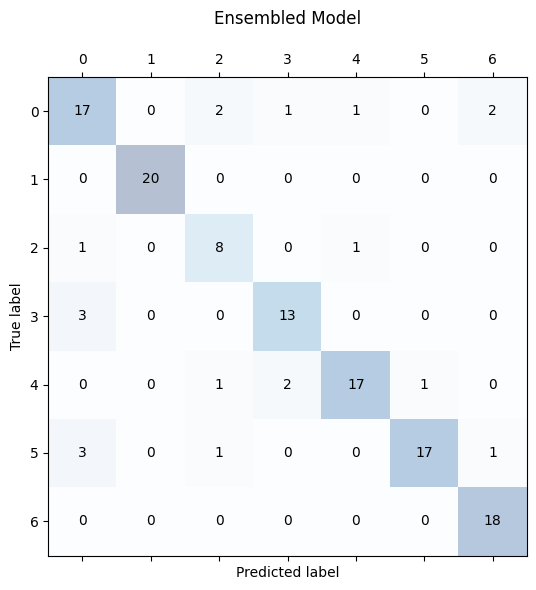

In [ ]:
cm = confusion_matrix(y_true = y_test, y_pred = final_predictions)

fig, ax = plt.subplots(figsize=(6, 6))
ax.matshow(cm, cmap=plt.cm.Blues, alpha=0.3)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(x=j, y=i, s=cm[i, j], va='center', ha='center')

ax.title.set_text('Ensembled Model\n')
plt.xlabel('Predicted label')
plt.ylabel('True label')

plt.tight_layout()
plt.savefig("ConfusionMatrix.png", dpi=300, format='png', pad_inches=0.3)
plt.show()

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

pScore = precision_score(y_true= y_test, y_pred = final_predictions, average = 'weighted')
print("Precision: ", pScore)

rScore = recall_score(y_true= y_test, y_pred = final_predictions, average = 'weighted')
print("Recall: ", rScore)

fScore = f1_score(y_true= y_test, y_pred = final_predictions, average = 'weighted')
print("F1-score: ", fScore)

print("\n\n\n")

Precision:  0.853493509414562
Recall:  0.8461538461538461
F1-score:  0.8467416135419409






In [ ]:
from tensorflow.keras.applications.inception_v3 import preprocess_input

target_size_model1 = (299, 299)
target_size_model2 = (224, 224)
target_size_model3 = (224, 224)

def Ensemble_Predict(img):
    # Resize the image based on model requirements
    img_model1 = tf.image.resize(img, target_size_model1)
    img_model2_3 = tf.image.resize(img, target_size_model2)

    # Preprocess the images based on the model requirements
    processed_img_model1 = preprocess_input(img_model1)
    processed_img_model2_3 = preprocess_input(img_model2_3)

    # Make predictions using the loaded models
    pred_model1 = Model1.predict(np.expand_dims(processed_img_model1, axis=0))
    pred_model2 = Model2.predict(np.expand_dims(processed_img_model2_3, axis=0))
    pred_model3 = Model3.predict(np.expand_dims(processed_img_model2_3, axis=0))

    # Combine predictions using majority voting
    predictions = [pred_model1, pred_model2, pred_model3]
    final_prediction = majority_voting(predictions)[0]

    predicted_class_name = class_label_dict.get(final_prediction)
    return predicted_class_name

In [ ]:
predicted= Ensemble_Predict(X_test_std[1])
print("Predicted Class:", predicted)

1/1 [==============================] - 2s 2s/step
Predicted Class: chinese-mountain-cat
